# Analisis Statistika Deskriptif Harga, Luas Tanah, dan Luas Bangunan Rumah di Jakarta Selatan
Kelompok 06 - 3TIF | Statistika dan Probabilitas

Library yang dipakai hanya **Pandas**, sesuai Lembar Perkuliahan Pertemuan 4.

Sebelum menjalankan: unggah file `HARGA_RUMAH_JAKSEL.xlsx` (data asli dari Kaggle) lewat panel **Files** di sebelah kiri Colab.

## A. Pengorganisasian Data
### A.1 Import data asli

In [ ]:
import pandas as pd

# Data asli dari Kaggle. Baris pertama file kosong, jadi header ada di baris ke-2 (header=1)
path = "HARGA RUMAH JAKSEL.xlsx"
dataraw = pd.read_excel(path, header=1)
print(dataraw)

            HARGA    LT   LB  JKT  JKM        GRS    KOTA
0     28000000000  1100  700    5    6        ADA  JAKSEL
1     19000000000   824  800    4    4        ADA  JAKSEL
2      4700000000   500  400    4    3        ADA  JAKSEL
3      4900000000   251  300    5    4        ADA  JAKSEL
4     28000000000  1340  575    4    5        ADA  JAKSEL
...           ...   ...  ...  ...  ...        ...     ...
996   16000000000   488  550    6    5        ADA  JAKSEL
997    4500000000   209  270    4    4        ADA  JAKSEL
998   29000000000   692  400    4    3  TIDAK ADA  JAKSEL
999    1700000000   102  140    4    3  TIDAK ADA  JAKSEL
1000   1250000000    63  110    3    3  TIDAK ADA  JAKSEL

[1001 rows x 7 columns]


In [ ]:
# Ukuran data dan tipe tiap kolom
print("Jumlah baris dan kolom:", dataraw.shape)
print(dataraw.dtypes)

Jumlah baris dan kolom: (1001, 7)
HARGA     int64
LT        int64
LB        int64
JKT       int64
JKM       int64
GRS      object
KOTA     object
dtype: object


### A.2 Pemeriksaan dan pembersihan data

In [ ]:
# Pemeriksaan nilai kosong dan baris duplikat
print("Nilai kosong per kolom:")
print(dataraw.isna().sum())
print("Jumlah baris duplikat:", dataraw.duplicated().sum())

Nilai kosong per kolom:
HARGA    0
LT       0
LB       0
JKT      0
JKM      0
GRS      0
KOTA     0
dtype: int64
Jumlah baris duplikat: 70


In [ ]:
# Hapus baris duplikat (kemunculan pertama dipertahankan)
data = dataraw.drop_duplicates().reset_index(drop=True)
print("Baris sebelum dibersihkan:", len(dataraw))
print("Baris duplikat dihapus   :", len(dataraw) - len(data))
print("Baris setelah dibersihkan:", len(data))

Baris sebelum dibersihkan: 1001
Baris duplikat dihapus   : 70
Baris setelah dibersihkan: 931


In [ ]:
# Harga dinyatakan dalam miliar rupiah agar mudah dibaca
data["HARGA_MILIAR"] = data["HARGA"] / 1_000_000_000
print(data.head(10))

         HARGA    LT   LB  JKT  JKM        GRS    KOTA  HARGA_MILIAR
0  28000000000  1100  700    5    6        ADA  JAKSEL         28.00
1  19000000000   824  800    4    4        ADA  JAKSEL         19.00
2   4700000000   500  400    4    3        ADA  JAKSEL          4.70
3   4900000000   251  300    5    4        ADA  JAKSEL          4.90
4  28000000000  1340  575    4    5        ADA  JAKSEL         28.00
5  10000000000   460  300    4    4        ADA  JAKSEL         10.00
6   7600000000   278  350    4    4        ADA  JAKSEL          7.60
7   5250000000   511  300    3    2        ADA  JAKSEL          5.25
8    670000000    70   69    3    2  TIDAK ADA  JAKSEL          0.67
9    480000000    66   42    2    1  TIDAK ADA  JAKSEL          0.48


### A.3 Tabel frekuensi ketersediaan garasi (GRS)

In [ ]:
frq_grs = pd.crosstab(index=data["GRS"], columns="Frekuensi")
frq_grs["Persentase"] = (frq_grs["Frekuensi"] / frq_grs["Frekuensi"].sum() * 100).round(1)
print(frq_grs)

col_0      Frekuensi  Persentase
GRS                             
ADA              714        76.7
TIDAK ADA        217        23.3


### A.4 Tabel frekuensi kelas harga

In [ ]:
# Harga dikelompokkan ke dalam kelas (miliar rupiah)
batas = [0, 5, 10, 20, 50, 1000]
label = ["< 5", "5 - < 10", "10 - < 20", "20 - < 50", ">= 50"]
data["KELAS_HARGA"] = pd.cut(data["HARGA_MILIAR"], bins=batas, labels=label, right=False)

frq_harga = pd.crosstab(index=data["KELAS_HARGA"], columns="Frekuensi")
frq_harga["Persentase"] = (frq_harga["Frekuensi"] / frq_harga["Frekuensi"].sum() * 100).round(1)
print(frq_harga)

col_0        Frekuensi  Persentase
KELAS_HARGA                       
< 5                134        14.4
5 - < 10           241        25.9
10 - < 20          312        33.5
20 - < 50          200        21.5
>= 50               44         4.7


### A.5 Tabel frekuensi jumlah kamar tidur (JKT) dan kamar mandi (JKM)

In [ ]:
frq_jkt = pd.crosstab(index=data["JKT"], columns="Frekuensi")
print(frq_jkt)

col_0  Frekuensi
JKT             
1              1
2             20
3            179
4            401
5            203
6             70
7             24
8             17
9              5
10             4
11             1
17             1
22             1
27             4


In [ ]:
frq_jkm = pd.crosstab(index=data["JKM"], columns="Frekuensi")
print(frq_jkm)

col_0  Frekuensi
JKM             
1             10
2             84
3            294
4            339
5            126
6             48
7             13
8              6
9              3
10             2
11             1
18             1
21             1
27             3


## B. Penyajian Data
### B.1 Ketersediaan garasi

<Axes: title={'center': 'Jumlah Rumah menurut Ketersediaan Garasi'}, xlabel='GRS'>

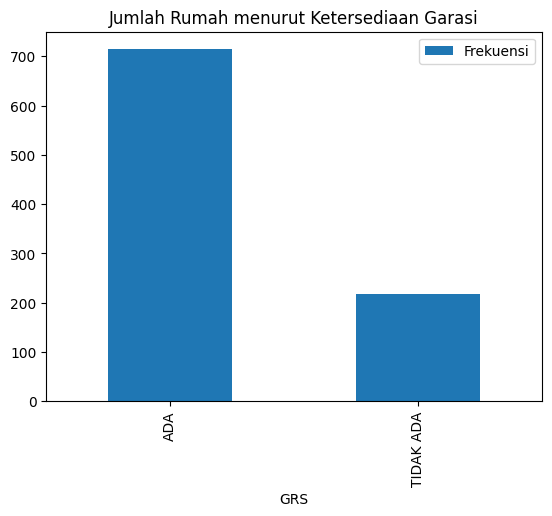

In [ ]:
# Grafik Batang
frq_grs.plot(kind="bar", y="Frekuensi", title="Jumlah Rumah menurut Ketersediaan Garasi")

<Axes: title={'center': 'Persentase Rumah menurut Ketersediaan Garasi'}>

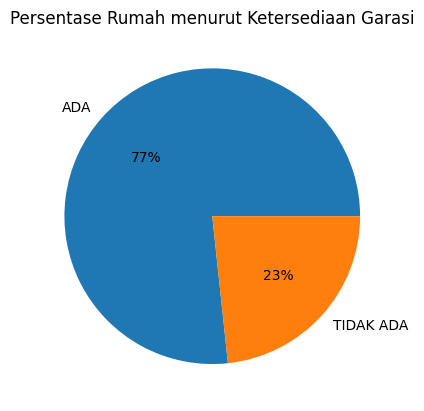

In [ ]:
# Pie Chart
frq_grs.plot(kind="pie", y="Frekuensi", autopct="%1.0f%%", legend=False, ylabel="",
             title="Persentase Rumah menurut Ketersediaan Garasi")

### B.2 Kelas harga

<Axes: title={'center': 'Frekuensi Rumah menurut Kelas Harga (Rp miliar)'}, xlabel='KELAS_HARGA'>

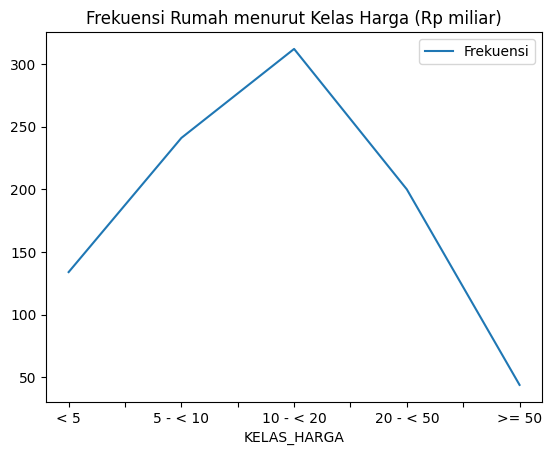

In [ ]:
# Grafik Garis
frq_harga.plot(y="Frekuensi", title="Frekuensi Rumah menurut Kelas Harga (Rp miliar)")

In [ ]:
# Grafik Batang
frq_harga.plot(kind="bar", y="Frekuensi", title="Frekuensi Rumah menurut Kelas Harga (Rp miliar)")

In [ ]:
# Pie Chart
frq_harga.plot(kind="pie", y="Frekuensi", autopct="%1.0f%%", legend=False, ylabel="",
               title="Persentase Rumah menurut Kelas Harga (Rp miliar)")

### B.3 Jumlah kamar tidur dan kamar mandi

In [ ]:
frq_jkt.plot(kind="bar", title="Frekuensi Jumlah Kamar Tidur (JKT)")

In [ ]:
frq_jkm.plot(kind="bar", title="Frekuensi Jumlah Kamar Mandi (JKM)")

### B.4 Histogram dan boxplot variabel utama

In [ ]:
data["HARGA_MILIAR"].plot(kind="hist", bins=40, title="Histogram Harga Rumah (Rp miliar)")

In [ ]:
data["HARGA_MILIAR"].plot(kind="box", title="Boxplot Harga Rumah (Rp miliar)")

In [ ]:
data["LT"].plot(kind="hist", bins=40, title="Histogram Luas Tanah (m2)")

In [ ]:
data["LT"].plot(kind="box", title="Boxplot Luas Tanah (m2)")

In [ ]:
data["LB"].plot(kind="hist", bins=40, title="Histogram Luas Bangunan (m2)")

In [ ]:
data["LB"].plot(kind="box", title="Boxplot Luas Bangunan (m2)")

## C. Statistika Deskriptif
### C.1 Harga (Rp miliar)

In [ ]:
#Statistika Deskriptif
dt = data["HARGA_MILIAR"]
stats = dt.describe()
stats['Standard Error'] = dt.sem()
stats['Median'] = dt.median()
stats['Mode'] = dt.mode().iloc[0]
stats['variance'] = dt.var()
stats['range'] = dt.max() - dt.min()
stats['IQR'] = dt.quantile(0.75) - dt.quantile(0.25)
stats['SD/Mean (%)'] = dt.std() / dt.mean() * 100
stats['skewness'] = dt.skew()
stats['kurtosis'] = dt.kurtosis()
stats_harga = stats
print(stats_harga.round(3))

### C.2 Luas tanah (m²)

In [ ]:
dt = data["LT"]
stats = dt.describe()
stats['Standard Error'] = dt.sem()
stats['Median'] = dt.median()
stats['Mode'] = dt.mode().iloc[0]
stats['variance'] = dt.var()
stats['range'] = dt.max() - dt.min()
stats['IQR'] = dt.quantile(0.75) - dt.quantile(0.25)
stats['SD/Mean (%)'] = dt.std() / dt.mean() * 100
stats['skewness'] = dt.skew()
stats['kurtosis'] = dt.kurtosis()
stats_lt = stats
print(stats_lt.round(3))

### C.3 Luas bangunan (m²)

In [ ]:
dt = data["LB"]
stats = dt.describe()
stats['Standard Error'] = dt.sem()
stats['Median'] = dt.median()
stats['Mode'] = dt.mode().iloc[0]
stats['variance'] = dt.var()
stats['range'] = dt.max() - dt.min()
stats['IQR'] = dt.quantile(0.75) - dt.quantile(0.25)
stats['SD/Mean (%)'] = dt.std() / dt.mean() * 100
stats['skewness'] = dt.skew()
stats['kurtosis'] = dt.kurtosis()
stats_lb = stats
print(stats_lb.round(3))

### C.4 Ringkasan ketiga variabel

In [ ]:
ringkasan = pd.DataFrame({"HARGA (Rp miliar)": stats_harga, "LT (m2)": stats_lt, "LB (m2)": stats_lb})
print(ringkasan.round(2))

### C.5 Deteksi outlier dengan aturan 1,5 × IQR

In [ ]:
for kolom in ["HARGA_MILIAR", "LT", "LB"]:
    q1 = data[kolom].quantile(0.25)
    q3 = data[kolom].quantile(0.75)
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    jumlah = ((data[kolom] < batas_bawah) | (data[kolom] > batas_atas)).sum()
    print(kolom)
    print("  Batas bawah    :", round(batas_bawah, 2))
    print("  Batas atas     :", round(batas_atas, 2))
    print("  Jumlah outlier :", jumlah)

### C.6 Statistika deskriptif harga menurut ketersediaan garasi

In [ ]:
stats_grs = data.groupby("GRS")["HARGA_MILIAR"].describe()
stats_grs["Median"] = data.groupby("GRS")["HARGA_MILIAR"].median()
stats_grs["range"] = stats_grs["max"] - stats_grs["min"]
stats_grs["IQR"] = stats_grs["75%"] - stats_grs["25%"]
print(stats_grs.round(2).T)

<Axes: title={'center': 'HARGA_MILIAR'}, xlabel='GRS'>

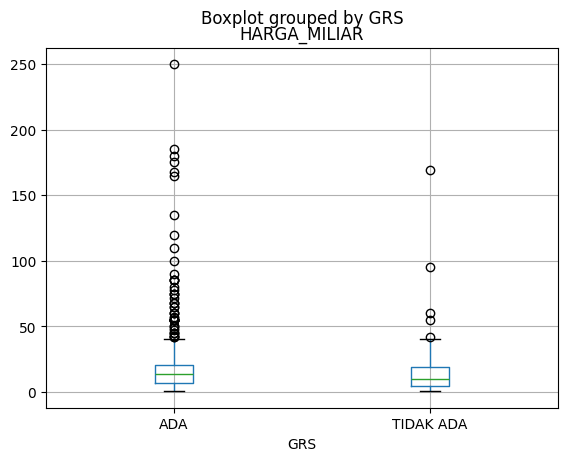

In [34]:
data.boxplot(column="HARGA_MILIAR", by="GRS")

In [33]:
print(data.groupby("GRS")[["LT", "LB"]].median())

              LT     LB
GRS                    
ADA        404.5  442.0
TIDAK ADA  340.0  350.0
